# 03 · Interpretação e decisão — o que o modelo vê e o que fazer com isso

Os notebooks anteriores mostraram **o que importa no jogo** (01, 02). As Etapas 5 e 6
escolheram o modelo: **regressão logística, sem calibração extra, com `diffs_core`**, e com
AUC de 0,807 no teste. Este notebook responde às perguntas do stakeholder:

1. **Por que** o modelo dá a probabilidade que dá? (SHAP global e local)
2. **Quando ele erra com convicção**, o que essas partidas têm em comum? (viradas)
3. **O que fazer** com a probabilidade? (faixas de decisão e cobertura × acerto)

**Dados:** faixas e SHAP usam o **teste** (1.976 partidas, que nenhum passo de modelagem viu).
Para as viradas, que são eventos raros, uso todas as predições **fora da amostra**: as do
teste mais as out-of-fold do treino (cada partida prevista por um modelo que não a viu).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from scipy import stats

from lol_win.analysis.eda import TEAM_PALETTE, save_figure, set_plot_style
from lol_win.analysis.interpret import (
    FEATURE_LABELS,
    confident_misses,
    coverage_accuracy_curve,
    decision_bands,
    orient_to_favorite,
    shap_explanation,
)
from lol_win.config import GOLD_TEST, GOLD_TRAIN, INPUT_COLUMNS, METRICS_DIR, TARGET
from lol_win.features.build import build_features
from lol_win.models.calibrate import Variant, build_variant, oof_probabilities
from lol_win.models.predict import load_metadata, load_model
from lol_win.models.tune import load_tuning_results

set_plot_style()
pd.set_option("display.float_format", "{:,.3f}".format)

/home/renan/projetos/lol-win-predictor/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
train, test = pd.read_parquet(GOLD_TRAIN), pd.read_parquet(GOLD_TEST)
X_train, y_train = train[list(INPUT_COLUMNS)], train[TARGET]
X_test, y_test = test[list(INPUT_COLUMNS)], test[TARGET]

model = load_model()
metadata = load_metadata()
p_test = model.predict_proba(X_test)[:, 1]

print(f"Modelo: {metadata['variant']} · features: {metadata['feature_set']}")
pd.DataFrame(metadata["test_metrics"]).T

Modelo: logreg · none · features: diffs_core


,value,ci_low,ci_high
roc_auc,0.807,0.789,0.825
log_loss,0.531,0.510,0.551
brier,0.180,0.171,0.188
accuracy,0.717,0.699,0.736
f1,0.718,0.697,0.740


---
## 1. SHAP global — o que pesa na probabilidade

Valores em **log-odds**: +1 em log-odds leva 50% a 73%; +2 leva a 88%. As features aparecem
nas unidades originais (gold em gold, dragões em dragões).

⚠️ **Ressalva:** o `LinearExplainer` trata as features como independentes. Gold, XP, kills e
nível são colineares (VIF 6–23, Notebook 01), então a divisão do crédito entre elas é uma
convenção do método, não uma verdade do jogo. **O bloco como um todo** é que é robusto.

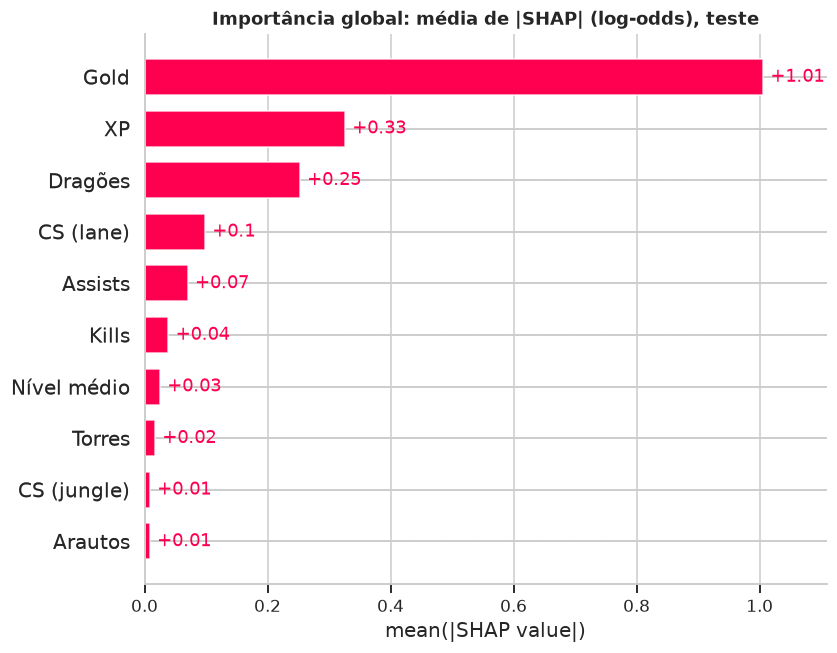

In [3]:
explanation = shap_explanation(model, X_test, background=X_train)

fig = plt.figure()
shap.plots.bar(explanation, max_display=12, show=False)
plt.title("Importância global: média de |SHAP| (log-odds), teste")
save_figure(plt.gcf(), "interp_shap_global_bar")
plt.show()

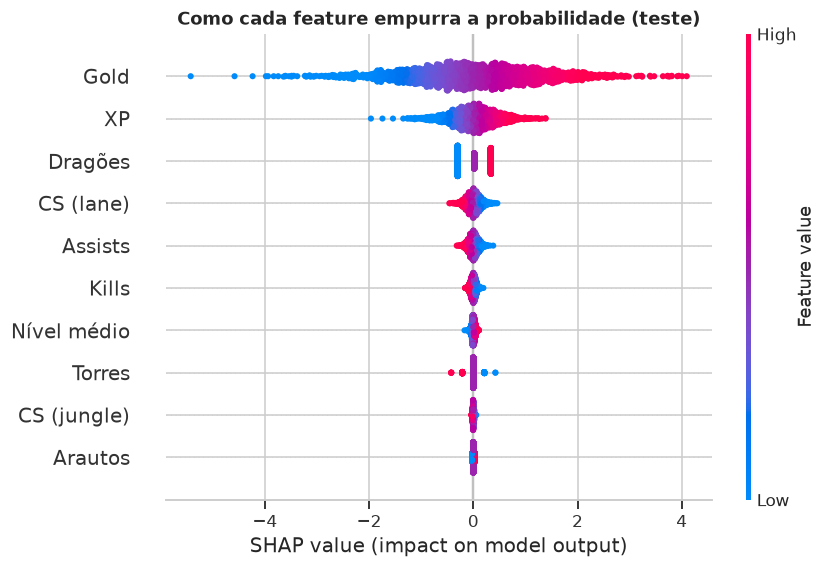

In [4]:
fig = plt.figure()
shap.plots.beeswarm(explanation, max_display=12, show=False)
plt.title("Como cada feature empurra a probabilidade (teste)")
save_figure(plt.gcf(), "interp_shap_beeswarm")
plt.show()

In [5]:
shap_values = np.asarray(explanation.values)  # noqa: PD011 (shap.Explanation)
importance = (
    pd.Series(np.abs(shap_values).mean(axis=0), index=explanation.feature_names)
    .sort_values(ascending=False)
    .to_frame("mean_abs_shap")
)
importance["share"] = importance["mean_abs_shap"] / importance["mean_abs_shap"].sum()
importance

,mean_abs_shap,share
Gold,1.006,0.543
XP,0.326,0.176
Dragões,0.253,0.136
CS (lane),0.098,0.053
Assists,0.070,0.038
Kills,0.039,0.021
Nível médio,0.025,0.014
Torres,0.017,0.009
CS (jungle),0.009,0.005
Arautos,0.009,0.005


**Leitura:**
- **Gold domina**, com cerca de metade de todo o "empurrão" do modelo. **XP** vem em segundo:
  ele corrige o gold que veio sem nível (o paradoxo da torre do Notebook 02).
- **Dragão** é o único objetivo com peso próprio relevante, coerente com o "+560 de gold"
  estimado na H2.
- Kills, assists, CS e torres aparecem com sinais que podem parecer estranhos (mais kills
  empurrando para **baixo**, com o gold fixo). É a colinearidade: dado o gold, um time que
  tem mais kills conseguiu menos gold com farm e objetivos. **Não leia esses sinais
  isoladamente.**

## 2. SHAP local — três partidas do teste

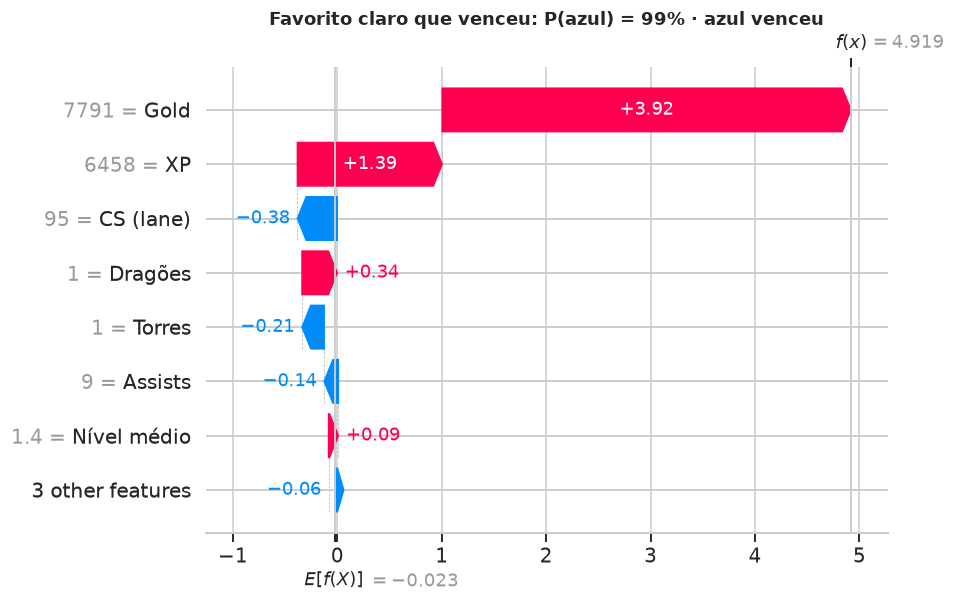

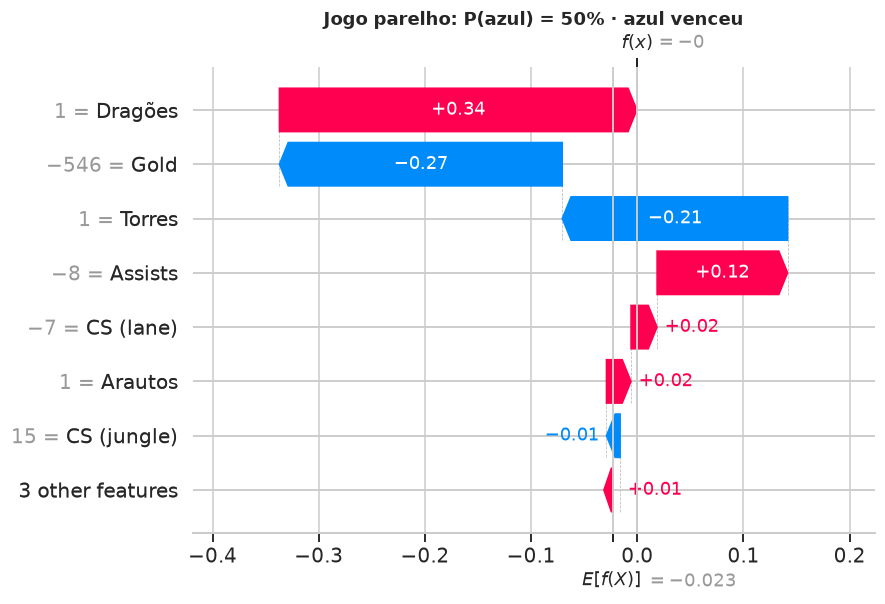

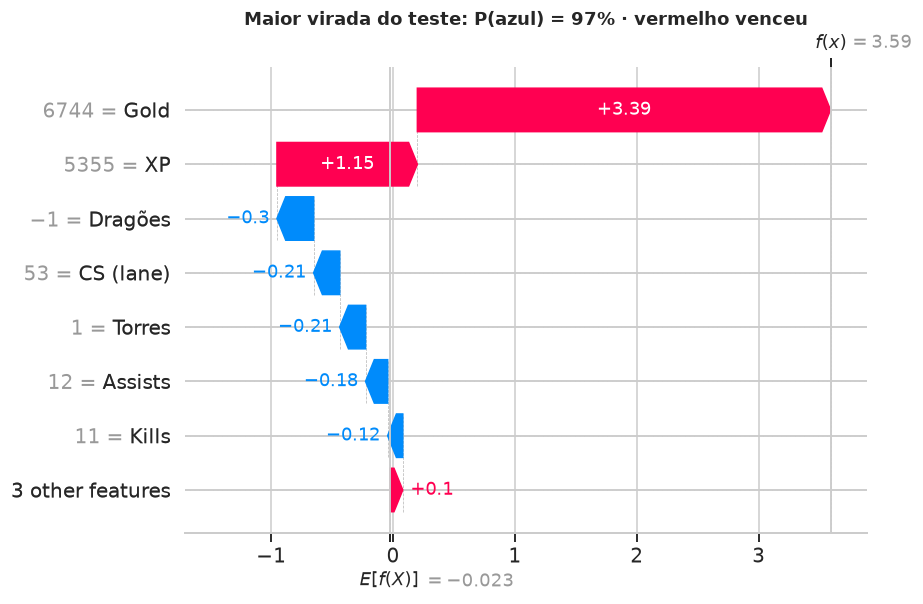

In [6]:
confidence_test = np.maximum(p_test, 1 - p_test)
hit_test = y_test.to_numpy() == (p_test >= 0.5)
examples = {
    "favorito_confirmado": int(np.argmax(np.where(hit_test & (p_test > 0.5), p_test, -1))),
    "jogo_parelho": int(np.argmin(np.abs(p_test - 0.5))),
    "virada": int(np.argmax(np.where(~hit_test, confidence_test, -1))),
}
titles = {
    "favorito_confirmado": "Favorito claro que venceu",
    "jogo_parelho": "Jogo parelho",
    "virada": "Maior virada do teste",
}
for key, idx in examples.items():
    outcome = "azul venceu" if y_test.iloc[idx] == 1 else "vermelho venceu"
    fig = plt.figure()
    shap.plots.waterfall(explanation[idx], max_display=8, show=False)
    plt.title(f"{titles[key]}: P(azul) = {p_test[idx]:.0%} · {outcome}")
    save_figure(plt.gcf(), f"interp_shap_waterfall_{key}")
    plt.show()

Como ler um waterfall: começa em **E[f(x)]** (o log-odds médio, perto de 0 = 50%), e cada
barra soma ou subtrai a contribuição de uma feature até chegar em **f(x)**, o log-odds daquela
partida. Vermelho empurra a favor do azul; azul empurra contra.

A "maior virada" é o caso que a transmissão mais teme: o modelo cravou mais de 90% e o time
perdeu. A seção seguinte pergunta se isso tem padrão.

---
## 3. Viradas — quando o modelo dá ≥ 80% e o favorito perde

Junto todas as predições fora da amostra: OOF do treino mais o teste (9.879 partidas).

In [7]:
tuning = load_tuning_results()[metadata["model"]]
final_estimator = build_variant(Variant(metadata["model"], "none"), tuning)
p_oof = oof_probabilities(final_estimator, X_train, y_train)

all_stats = pd.concat([train, test], ignore_index=True)
y_all = all_stats[TARGET].to_numpy()
p_all = np.concatenate([p_oof, p_test])
confidence = np.maximum(p_all, 1 - p_all)
confident = confidence >= 0.80
flipped = confident_misses(y_all, p_all, threshold=0.80)

print(f"Partidas com favorito ≥ 80%: {confident.sum():,} ({confident.mean():.1%} do total)")
print(f"Viradas: {flipped.sum():,} → {flipped.sum() / confident.sum():.1%} dessas partidas")
print(f"Confiança média nessas partidas: {confidence[confident].mean():.1%}")
print(f"Taxa de virada esperada se calibrado: {1 - confidence[confident].mean():.1%}")

Partidas com favorito ≥ 80%: 3,499 (35.4% do total)
Viradas: 407 → 11.6% dessas partidas
Confiança média nessas partidas: 88.8%
Taxa de virada esperada se calibrado: 11.2%


**Primeiro achado:** a taxa de virada (11,6%) é quase exatamente a esperada para um modelo
calibrado (~11%). Quando o modelo diz "89%", ele **quer dizer** que 1 em cada 9 vira.

**O que as viradas têm em comum?** Comparo as vantagens do favorito (em diffs orientadas a
ele) entre partidas que viraram e que se mantiveram. A comparação ingênua é enganosa:
viradas tendem a vir de confiança menor. Por isso comparo **dentro da mesma faixa de
confiança** (estratos de 5 p.p.) e faço a média ponderada.

In [8]:
oriented = orient_to_favorite(build_features(all_stats, "diffs"), p_all)
pool = oriented[confident].assign(
    virou=flipped[confident],
    stratum=pd.cut(confidence[confident], [0.80, 0.85, 0.90, 0.95, 1.0], include_lowest=True),
)
compare_cols = list(oriented.columns)


def stratified_gap(frame: pd.DataFrame, column: str) -> tuple[float, float, float]:
    """Diferença virou − segurou, média ponderada nos estratos, em desvios-padrão."""
    sd = frame[column].std()
    gaps, weights, pvals = [], [], []
    for _, group in frame.groupby("stratum", observed=True):
        flip, held = group.loc[group["virou"], column], group.loc[~group["virou"], column]
        if len(flip) < 5:
            continue
        gaps.append((flip.mean() - held.mean()) / sd)
        weights.append(len(flip))
        pvals.append(stats.ttest_ind(flip, held, equal_var=False).pvalue)
    combined_p = stats.combine_pvalues(pvals, method="stouffer").pvalue if pvals else np.nan
    return float(np.average(gaps, weights=weights)), float(sd), float(combined_p)


flip_mean = pool.loc[pool["virou"], compare_cols].mean()
held_mean = pool.loc[~pool["virou"], compare_cols].mean()
naive = (flip_mean - held_mean) / pool[compare_cols].std()
strat = pd.DataFrame(
    [stratified_gap(pool, c) for c in compare_cols],
    index=compare_cols,
    columns=["gap_estratificado", "sd", "p_estratificado"],
)
comebacks = pd.DataFrame({"gap_ingenuo": naive}).join(
    strat[["gap_estratificado", "p_estratificado"]]
)
comebacks.index = [FEATURE_LABELS.get(c, "First blood do favorito") for c in comebacks.index]
comebacks.sort_values("gap_ingenuo")

,gap_ingenuo,gap_estratificado,p_estratificado
Gold,-0.442,-0.012,0.015
XP,-0.379,-0.011,0.119
Kills,-0.354,-0.021,0.588
Nível médio,-0.315,-0.004,0.724
Assists,-0.254,-0.064,0.101
Dragões,-0.203,-0.146,0.159
CS (lane),-0.145,0.027,0.756
Torres,-0.127,-0.008,0.113
CS (jungle),-0.082,-0.026,0.595
Wards colocadas,-0.052,-0.045,0.466


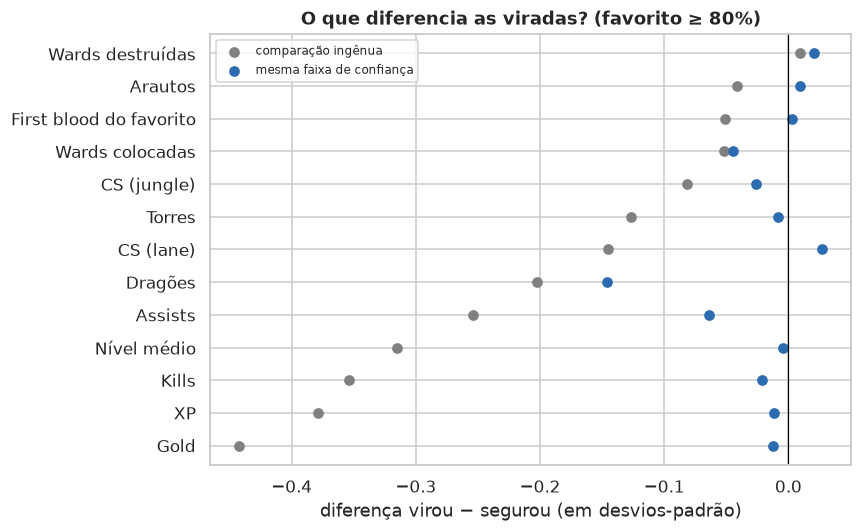

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
order = comebacks.sort_values("gap_ingenuo").index
y_pos = np.arange(len(order))
ax.scatter(comebacks.loc[order, "gap_ingenuo"], y_pos, color="grey", label="comparação ingênua")
ax.scatter(
    comebacks.loc[order, "gap_estratificado"],
    y_pos,
    color=TEAM_PALETTE["blue"],
    label="mesma faixa de confiança",
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(y_pos, order)
ax.set(
    xlabel="diferença virou − segurou (em desvios-padrão)",
    title="O que diferencia as viradas? (favorito ≥ 80%)",
)
ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "interp_comebacks_profile")
plt.show()

**Leitura:**
- Na comparação ingênua, as viradas têm vantagens um pouco menores em tudo: são os
  "favoritos fracos" dentro do grupo de ≥ 80%.
- **Dentro da mesma faixa de confiança, as diferenças praticamente somem**: gold vai de
  −0,44 para −0,01 desvio-padrão, e XP de −0,38 para −0,01. É o esperado: os resíduos de uma
  regressão logística bem ajustada são, por construção, não correlacionados com as features
  que ela usa. O maior gap restante (dragões, −0,15 DP) não é significativo (p ≈ 0,16), e o p
  de 0,015 do gold vem de um efeito minúsculo (0,01 DP) que não sobrevive a 13 comparações.
- Variáveis que o modelo **não** usa (wards, first blood) também não separam as viradas.

🎮 **Em linguagem de jogador:** *as viradas não são um ponto cego do snapshot dos 10 minutos.
São o jogo acontecendo depois dele*: teamfight decisiva, composição que escala, baron roubado,
erro de macro. Nada disso existe no dado aos 10 min. Para prever melhor as viradas, seria
preciso **outro dado** (composição e estado por minuto), não outro modelo. Isso alimenta os
"próximos passos" do README.

---
## 4. Faixas de decisão

Faixas fixas *a priori* (CLAUDE.md), sem nenhum ajuste no teste. "Acerto do favorito" = o
lado com P ≥ 50% venceu.

In [10]:
bands_test = decision_bands(y_test, p_test)
bands_oof = decision_bands(y_train, p_oof)
bands_test.to_csv(METRICS_DIR / "decision_bands.csv", float_format="%.4f")
stability = bands_oof[["share", "favorite_accuracy"]]
pd.concat({"teste": bands_test, "OOF treino (estabilidade)": stability}, axis=1)

teste                                                  \
           n share mean_pred blue_win_rate favorite_accuracy   
band                                                           
<15%     253 0.128     0.082         0.059             0.941   
15–35%   419 0.212     0.252         0.277             0.723   
35–65%   618 0.313     0.499         0.503             0.537   
65–85%   414 0.210     0.752         0.713             0.713   
>85%     272 0.138     0.913         0.915             0.915   

                                                OOF treino (estabilidade)  \
       favorite_acc_ci_low favorite_acc_ci_high                     share   
band                                                                        
<15%                 0.904                0.964                     0.125   
15–35%               0.678                0.764                     0.213   
35–65%               0.498                0.576                     0.327   
65–85%               0.667                0.754                     0.214   
>85%                 0.876                0.943                     0.120   

                          
       favorite_accuracy  
band                      
<15%               0.906  
15–35%             0.751  
35–65%             0.586  
65–85%             0.757  
>85%               0.910

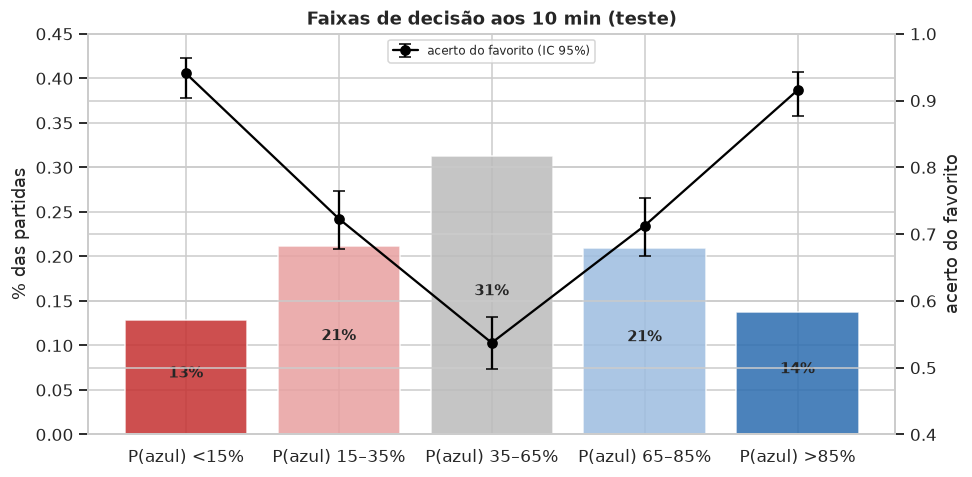

In [11]:
fig, ax1 = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(bands_test))
colors = [TEAM_PALETTE["red"], "#E8A0A0", "#BBBBBB", "#9DBCE0", TEAM_PALETTE["blue"]]
ax1.bar(x, bands_test["share"], color=colors, alpha=0.85)
ax1.set_ylabel("% das partidas")
ax1.set_ylim(0, 0.45)
for i, share in enumerate(bands_test["share"]):
    ax1.text(i, share / 2, f"{share:.0%}", ha="center", fontsize=10, fontweight="bold")
ax2 = ax1.twinx()
ax2.errorbar(
    x,
    bands_test["favorite_accuracy"],
    yerr=[
        bands_test["favorite_accuracy"] - bands_test["favorite_acc_ci_low"],
        bands_test["favorite_acc_ci_high"] - bands_test["favorite_accuracy"],
    ],
    color="black",
    marker="o",
    capsize=4,
    label="acerto do favorito (IC 95%)",
)
ax2.set_ylim(0.4, 1.0)
ax2.set_ylabel("acerto do favorito")
ax2.legend(loc="upper center", fontsize=8)
ax1.set_xticks(x, [f"P(azul) {b}" for b in bands_test.index])
ax1.set_title("Faixas de decisão aos 10 min (teste)")
fig.tight_layout()
save_figure(fig, "interp_decision_bands")
plt.show()

In [12]:
decided = bands_test.loc[["<15%", ">85%"]]
decided_share = decided["n"].sum() / len(y_test)
decided_accuracy = (decided["favorite_accuracy"] * decided["n"]).sum() / decided["n"].sum()
open_band = bands_test.loc["35–65%"]
open_share, open_acc = open_band["share"], open_band["favorite_accuracy"]
print(f"Jogo 'decidido' (<15% ou >85%): {decided_share:.1%} das partidas", end=" · ")
print(f"acerto {decided_accuracy:.1%}")
print(f"Jogo 'em aberto' (35–65%): {open_share:.1%} das partidas · acerto {open_acc:.1%}")

Jogo 'decidido' (<15% ou >85%): 26.6% das partidas · acerto 92.8%
Jogo 'em aberto' (35–65%): 31.3% das partidas · acerto 53.7%


**Frase de negócio:** *aos 10 minutos, dá para cravar o vencedor em ~27% das partidas, com
~93% de acerto. Em ~31% delas o jogo está genuinamente aberto: o favorito acerta só ~54%,
quase uma moeda.*

A tabela OOF do treino reproduz as mesmas proporções e acertos: as faixas são estáveis, não um
acaso do teste.

## 5. Cobertura × acerto — escolhendo o corte do "jogo decidido"

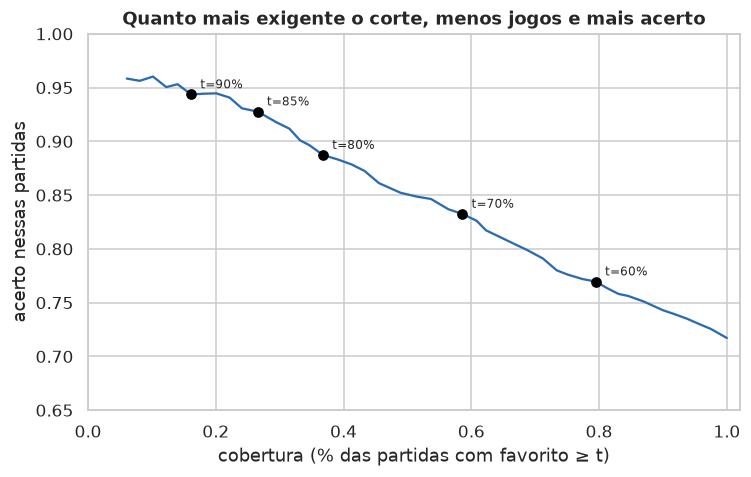

,threshold,coverage,n,accuracy
0,0.500,1.000,1976,0.717
10,0.600,0.795,1571,0.770
20,0.700,0.586,1158,0.832
25,0.750,0.473,934,0.857
30,0.800,0.368,727,0.887
35,0.850,0.266,525,0.928
40,0.900,0.161,319,0.944
45,0.950,0.061,120,0.958


In [13]:
curve = coverage_accuracy_curve(y_test, p_test)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(curve["coverage"], curve["accuracy"], color=TEAM_PALETTE["blue"])
for t in (0.6, 0.7, 0.8, 0.85, 0.9):
    row = curve.loc[np.isclose(curve["threshold"], t)].iloc[0]
    ax.scatter(row["coverage"], row["accuracy"], color="black", zorder=3)
    ax.annotate(
        f"t={t:.0%}",
        (row["coverage"], row["accuracy"]),
        textcoords="offset points",
        xytext=(6, 4),
        fontsize=8,
    )
ax.set(
    xlabel="cobertura (% das partidas com favorito ≥ t)",
    ylabel="acerto nessas partidas",
    title="Quanto mais exigente o corte, menos jogos e mais acerto",
    xlim=(0, 1.02),
    ylim=(0.65, 1.0),
)
fig.tight_layout()
save_figure(fig, "interp_coverage_accuracy")
plt.show()
curve[curve["threshold"].isin([0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95])]

---
## 6. O que isso significa para os três usos

| Uso | Recomendação |
|---|---|
| **Barra de win-probability na transmissão** | Usar a probabilidade direto: é calibrada (ECE 0,03 no teste). Mostrar arredondada a 5 p.p. para não sugerir uma precisão que não existe |
| **Indicador de "jogo decidido" (contexto do surrender aos 15)** | Corte em **85%**: ~27% das partidas, ~93% de acerto. Para um aviso mais conservador, 90% dá ~16% das partidas com ~94%. Mesmo no corte mais alto, **1 em cada ~14 "decididos" vira**, então o indicador deve dizer "muito provável", nunca "acabou" |
| **Equilíbrio de lados e objetivos** | Lado: sem vantagem mensurável (H1). Dragão: ~560 de gold de valor além do gold (H2); é o único objetivo com peso próprio. Arauto e torre: o valor deles já está no gold |

**Limitações que o stakeholder precisa saber:**
- Snapshot único aos 10 min: sem composição, sem picks/bans, sem estado por minuto.
- Elo alto e patch desconhecido. Mudanças de patch (valor do dragão, bounty) podem deslocar
  a calibração, então é preciso monitorar.
- SHAP explica o **modelo**, não o jogo: atribuições entre gold, XP e kills são uma convenção
  (colinearidade).